In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.read_csv("../data/raw/startup data.csv")

In [3]:
plt.figure(figsize=(7, 5))

<Figure size 700x500 with 0 Axes>

<Figure size 700x500 with 0 Axes>

C:\Users\Hp\AppData\Local\Temp\ipykernel_8472\4195584903.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


<Axes: xlabel='status', ylabel='count'>

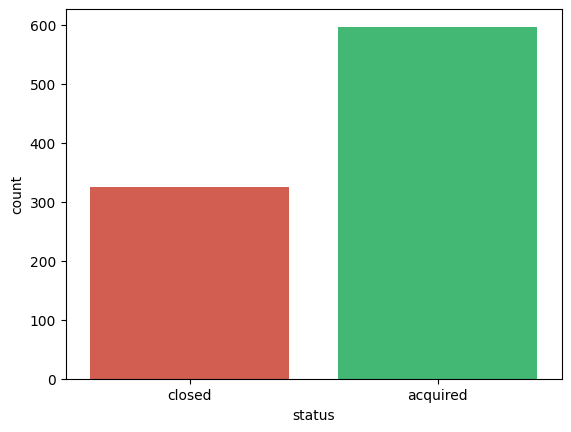

In [4]:
sns.countplot(
    data=df,
    x="status",
    order=["closed", "acquired"],
    palette=["#e74c3c", "#2ecc71"]
)

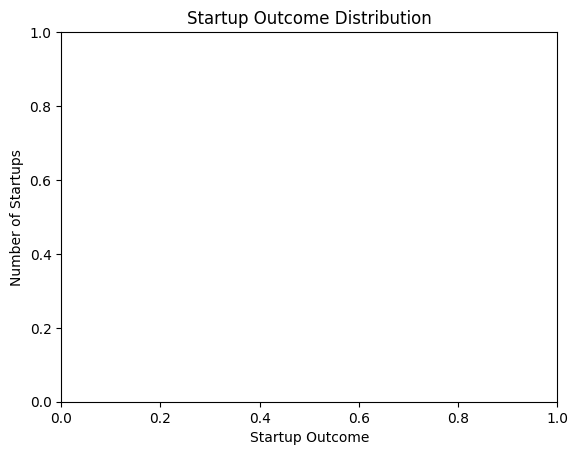

In [5]:

plt.title("Startup Outcome Distribution")
plt.xlabel("Startup Outcome")
plt.ylabel("Number of Startups")
plt.show()

C:\Users\Hp\AppData\Local\Temp\ipykernel_8472\3887192003.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


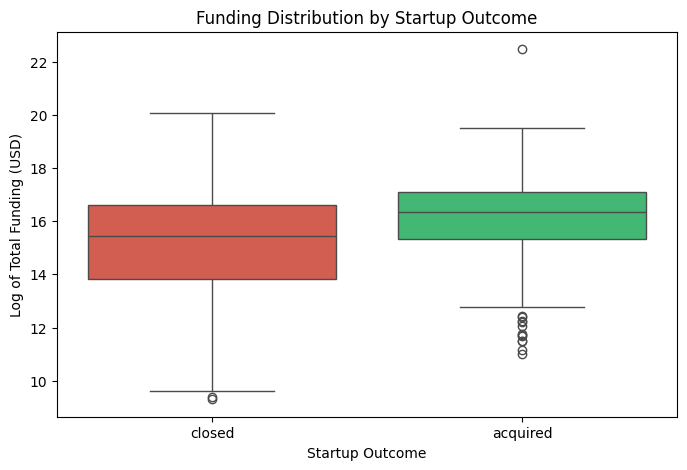

In [6]:
import numpy as np

plot_data = df.copy()

plot_data["log_funding"] = np.log1p(plot_data["funding_total_usd"])

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=plot_data,
    x="status",
    y="log_funding",
    order=["closed", "acquired"],
    palette=["#e74c3c", "#2ecc71"]
)

plt.title("Funding Distribution by Startup Outcome")
plt.xlabel("Startup Outcome")
plt.ylabel("Log of Total Funding (USD)")
plt.show()

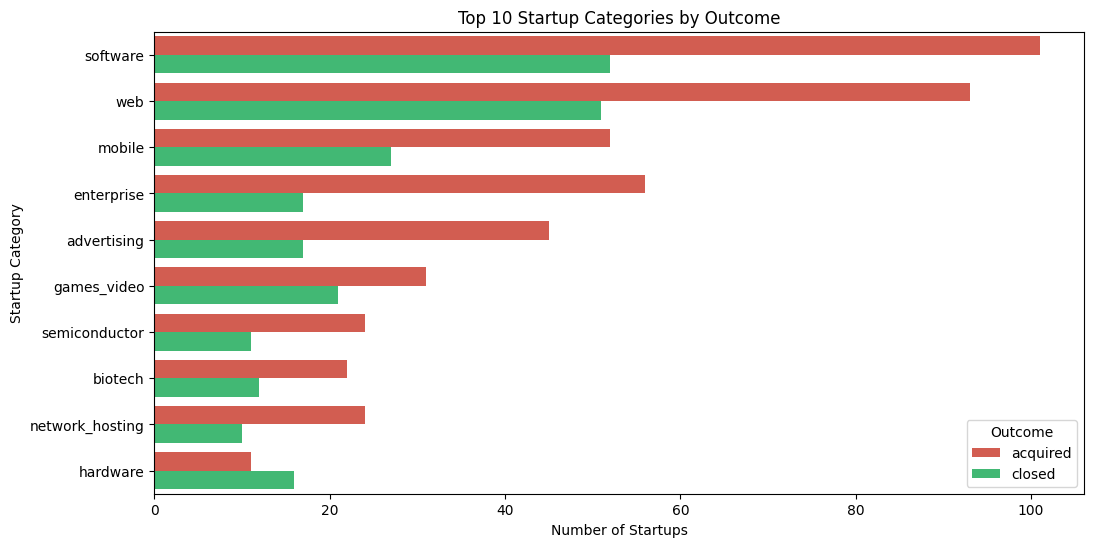

In [7]:
top_categories = df["category_code"].value_counts().head(10).index

category_data = df[df["category_code"].isin(top_categories)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=category_data,
    y="category_code",
    hue="status",
    order=top_categories,
    palette=["#e74c3c", "#2ecc71"]
)

plt.title("Top 10 Startup Categories by Outcome")
plt.xlabel("Number of Startups")
plt.ylabel("Startup Category")
plt.legend(title="Outcome")
plt.show()

C:\Users\Hp\AppData\Local\Temp\ipykernel_8472\3949847747.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


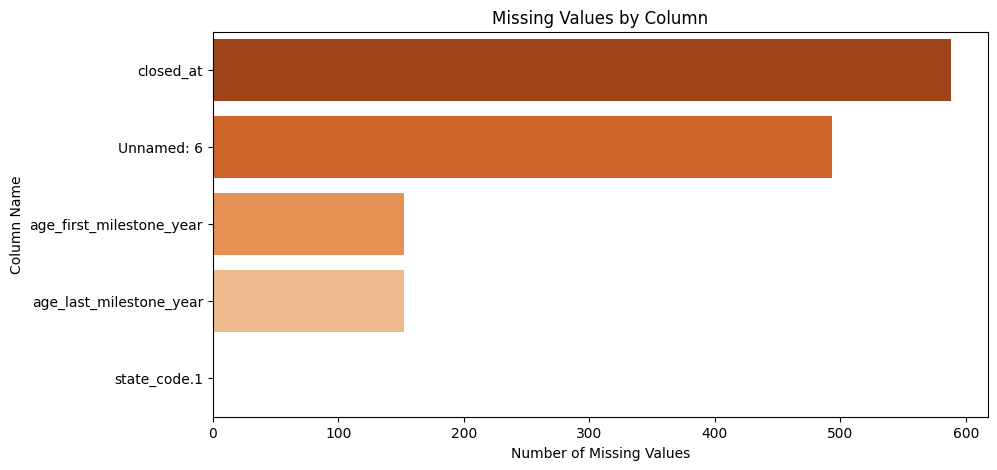

In [8]:
missing_data = df.isnull().sum()

missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_data.values,
    y=missing_data.index,
    palette="Oranges_r"
)

plt.title("Missing Values by Column")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column Name")
plt.show()

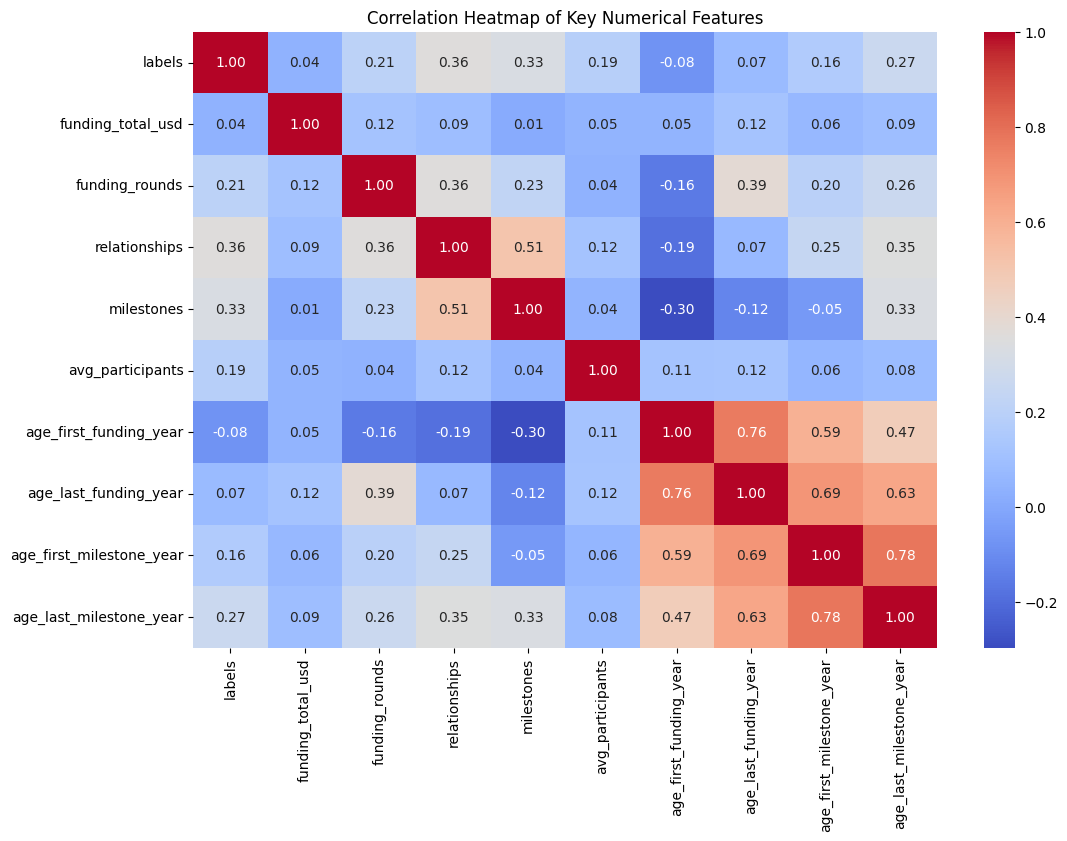

In [9]:
correlation_columns = [
    "labels",
    "funding_total_usd",
    "funding_rounds",
    "relationships",
    "milestones",
    "avg_participants",
    "age_first_funding_year",
    "age_last_funding_year",
    "age_first_milestone_year",
    "age_last_milestone_year"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Key Numerical Features")
plt.show()

In [10]:
Q1 = df["funding_total_usd"].quantile(0.25)

Q3 = df["funding_total_usd"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["funding_total_usd"] < lower_limit) |
    (df["funding_total_usd"] > upper_limit)
]

print("Number of funding outliers:", len(outliers))

Number of funding outliers: 65


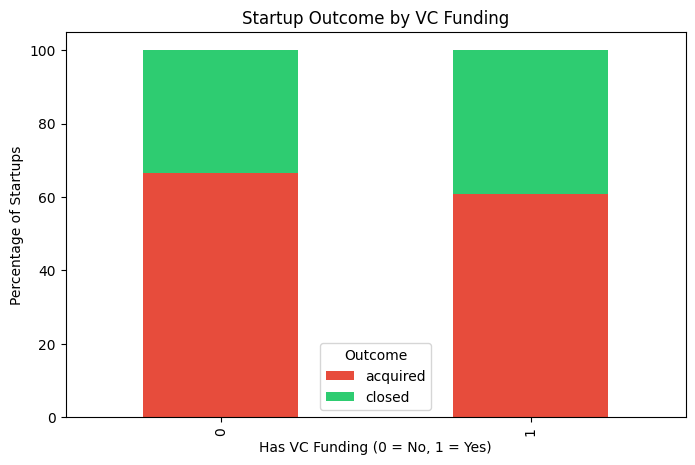

In [11]:
vc_outcome = pd.crosstab(
    df["has_VC"],
    df["status"],
    normalize="index"
) * 100

vc_outcome.plot(
    kind="bar",
    stacked=True,
    color=["#e74c3c", "#2ecc71"],
    figsize=(8, 5)
)

plt.title("Startup Outcome by VC Funding")
plt.xlabel("Has VC Funding (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Startups")
plt.legend(title="Outcome")
plt.show()

C:\Users\Hp\AppData\Local\Temp\ipykernel_8472\1704679453.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


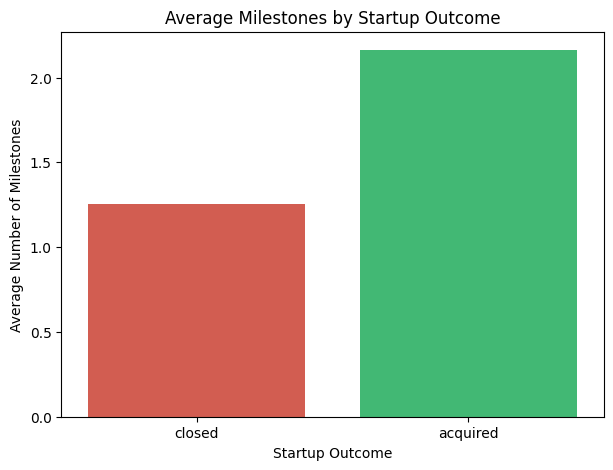

In [12]:
milestone_summary = df.groupby("status")["milestones"].mean().reset_index()

plt.figure(figsize=(7, 5))

sns.barplot(
    data=milestone_summary,
    x="status",
    y="milestones",
    order=["closed", "acquired"],
    palette=["#e74c3c", "#2ecc71"]
)

plt.title("Average Milestones by Startup Outcome")
plt.xlabel("Startup Outcome")
plt.ylabel("Average Number of Milestones")
plt.show()

In [13]:
feature_engineered_df = df.copy()

feature_engineered_df["funding_per_round"] = np.where(
    feature_engineered_df["funding_rounds"] > 0,
    feature_engineered_df["funding_total_usd"] / feature_engineered_df["funding_rounds"],
    0
)

feature_engineered_df[
    ["funding_total_usd", "funding_rounds", "funding_per_round"]
].head()

,funding_total_usd,funding_rounds,funding_per_round
0,375000,3,1.250000e+05
1,40100000,4,1.002500e+07
2,2600000,1,2.600000e+06
3,40000000,3,1.333333e+07
4,1300000,2,6.500000e+05


In [14]:
feature_engineered_df["funding_duration_years"] = (
    feature_engineered_df["age_last_funding_year"]
    - feature_engineered_df["age_first_funding_year"]
)

feature_engineered_df[
    [
        "age_first_funding_year",
        "age_last_funding_year",
        "funding_duration_years"
    ]
].head()

,age_first_funding_year,age_last_funding_year,funding_duration_years
0,2.2493,3.0027,0.7534
1,5.1260,9.9973,4.8713
2,1.0329,1.0329,0.0000
3,3.1315,5.3151,2.1836
4,0.0000,1.6685,1.6685


In [15]:
funding_stage_columns = [
    "has_roundA",
    "has_roundB",
    "has_roundC",
    "has_roundD"
]

feature_engineered_df["advanced_funding_rounds"] = (
    feature_engineered_df[funding_stage_columns].sum(axis=1)
)

feature_engineered_df[
    funding_stage_columns + ["advanced_funding_rounds"]
].head()

,has_roundA,has_roundB,has_roundC,has_roundD,advanced_funding_rounds
0,0,0,0,0,0
1,0,1,1,1,3
2,1,0,0,0,1
3,0,1,1,1,3
4,0,0,0,0,0
